# Exploratory Data Analysis: Online News Shares (Regression)

## Objective
Each row is a news article. The goal is to **predict `shares`**, the number of times an article was shared. Because `shares` is a continuous count, this is a **regression** problem.

Every other column is a candidate independent variable (x). This notebook decides which of them to keep for model training, through four stages:

1. **Data exploration**: what each column is and where the problems are
2. **Data cleaning**: duplicates, missing values, invalid values, and new features
3. **Univariate analysis**: the distribution of each variable on its own
4. **Bivariate and correlation analysis**: how each feature relates to `shares` and to the other features

The notebook ends with a feature keep/drop table that will feed `src/config.yaml` and `src/data_preparation.py`.

| Family | Columns |
|---|---|
| Identifiers | `ID`, `URL` |
| Time / channel | `timedelta`, `weekday`, `data_channel` |
| Text | `n_tokens_title`, `n_tokens_content`, `n_unique_tokens`, `n_non_stop_words`, `n_non_stop_unique_tokens`, `average_token_length` |
| Links / media | `num_hrefs`, `num_self_hrefs`, `num_imgs`, `num_videos` |
| Engagement | `n_comments` |
| Self-reference | `self_reference_min_shares`, `self_reference_max_shares`, `self_reference_avg_shares` |
| Keywords | `num_keywords`, `kw_{min,max,avg}_{min,max,avg}` (9 columns) |
| **Target** | `shares` |

## 1. Load the data

**What:** Import the analysis libraries and load `mini_project_1_data.csv` into a DataFrame.

**Why:** Everything that follows works on this DataFrame, `df`.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_csv('./data/mini_project_1_data.csv')
df.head()

,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,n_comments,average_token_length,data_channel,self_reference_min_shares,self_reference_max_shares,self_reference_avg_shares,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,monday,593,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,0.0,4.680365,entertainment,496.0,496.0,496.000000,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,monday,711,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,NaN,28.0,4.913725,business,0.0,0.0,0.000000,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,monday,1500,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,15.0,4.393365,business,918.0,918.0,918.000000,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,monday,1200,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,0.0,72.0,4.404896,entertainment,0.0,0.0,0.000000,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,monday,505,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,NaN,20.0,4.682836,technology,545.0,16000.0,3151.157895,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. First look at the data

**What:** Inspect the data types, the missing-value counts, the summary statistics and the number of unique values per column.

**Why:** Before cleaning anything we need to know what each column is and where the problems are, such as missing values, impossible values or columns that barely vary.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  str    
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  str    
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_videos                 18925 non-null  float64
 14  n

In [3]:
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, 'pct': (missing / len(df) * 100).round(2)})[missing > 0]

,missing,pct
num_hrefs,721,2.02
num_self_hrefs,721,2.02
num_imgs,1419,3.98
num_videos,16755,46.96
data_channel,5462,15.31
self_reference_min_shares,721,2.02
self_reference_max_shares,721,2.02
self_reference_avg_shares,721,2.02


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,35680.0,19823.468918,11452.292291,0.0,9890.750000,19801.500000,29788.250000,39643.000000
timedelta,35680.0,354.523234,214.301086,8.0,163.000000,339.000000,543.000000,731.000000
shares,35680.0,3402.054961,11934.878541,4.0,946.000000,1400.000000,2800.000000,843300.000000
n_tokens_title,35680.0,10.395432,2.114600,2.0,9.000000,10.000000,12.000000,23.000000
n_tokens_content,35680.0,545.995123,469.550052,0.0,247.000000,410.000000,716.000000,8474.000000
n_unique_tokens,35680.0,0.530461,0.136935,0.0,0.471030,0.539011,0.608203,1.000000
n_non_stop_words,35680.0,0.970263,0.169862,0.0,1.000000,1.000000,1.000000,1.000000
n_non_stop_unique_tokens,35680.0,0.672738,0.153881,0.0,0.625912,0.690323,0.754036,1.000000
num_hrefs,34959.0,10.866358,11.260971,0.0,4.000000,8.000000,14.000000,304.000000
num_self_hrefs,34959.0,3.282531,3.834065,0.0,1.000000,3.000000,4.000000,116.000000


In [5]:
df.nunique().sort_values()

data_channel                     6
weekday                          7
num_keywords                    10
n_tokens_title                  20
kw_min_min                      22
kw_max_max                      31
num_videos                      46
num_self_hrefs                  57
num_imgs                        89
num_hrefs                      128
timedelta                      724
n_comments                     834
kw_min_max                    1006
kw_max_min                    1064
self_reference_max_shares     1119
self_reference_min_shares     1231
shares                        1418
n_non_stop_words              1429
n_tokens_content              2324
self_reference_avg_shares     7853
kw_min_avg                   14686
kw_avg_min                   15949
kw_max_avg                   18053
n_non_stop_unique_tokens     21345
n_unique_tokens              25197
average_token_length         27595
kw_avg_max                   28284
kw_avg_avg                   35394
ID                  

**What we found:**
- **35,680 rows × 30 columns.** Only `URL`, `weekday` and `data_channel` are text; everything else is numeric.
- **Missing values in 8 columns:** `num_videos` (16,755, **47%**), `data_channel` (5,462, 15%), `num_imgs` (1,419, 4%), and `num_hrefs`, `num_self_hrefs` and the three `self_reference_*` columns (721 each, 2%).
- **The target is extremely skewed:** the median is 1,400 shares but the mean is ~3,400 and the maximum is 843,300.
- **Negative values** appear in `kw_min_min`, `kw_avg_min` and `kw_min_avg` (minimum −1). A share count cannot be negative, so −1 is a placeholder.
- `n_tokens_content` has a minimum of **0**: some articles have no text at all.
- `n_non_stop_words` has a mean of 0.97 and a median of 1: almost every value is (very close to) 1, so it barely varies.

**How this affects the next step:** Section 3 deals with each of these issues in turn.

## 3. Data cleaning

### 3.1 Duplicate rows

**What:** Count fully duplicated rows, then duplicates on `ID`, on `URL`, and on all columns except `ID`.

**Why:** A repeated article would be counted twice and over-weight its share count. Checking everything except `ID` also catches the same article re-loaded under a new ID.

In [6]:
print('Fully duplicated rows      :', df.duplicated().sum())
print('Duplicated ID              :', df['ID'].duplicated().sum())
print('Duplicated URL             :', df['URL'].duplicated().sum())
print('Duplicated (ignoring ID)   :', df.drop(columns='ID').duplicated().sum())

Fully duplicated rows      : 0
Duplicated ID              : 0
Duplicated URL             : 0
Duplicated (ignoring ID)   : 0


**What we found:** There are **no duplicates** under any of the four definitions. Every row is a separate article.

**How this affects the next step:** Nothing needs to be removed, so we move on to missing values.

### 3.2 Missing values

**What:** First check whether the 721-row gaps in the link columns fall on the same rows. Then, for each column with gaps, compare the shares of rows with and without a value.

**Why:** If the gaps overlap, they share one cause and should get one fix. If rows with missing values have different shares, the missingness itself carries information and we should not just drop those rows.

In [7]:
link_cols = ['num_hrefs', 'num_self_hrefs', 'self_reference_min_shares',
             'self_reference_max_shares', 'self_reference_avg_shares']
print('Rows missing any link column:', df[link_cols].isnull().any(axis=1).sum())
print('Rows missing all link columns:', df[link_cols].isnull().all(axis=1).sum())

# When an article has no self-links, are the self_reference_* values already 0?
no_self_links = df['num_self_hrefs'] == 0
print('self_reference_avg_shares == 0 when num_self_hrefs == 0:',
      (df.loc[no_self_links, 'self_reference_avg_shares'] == 0).mean())

Rows missing any link column: 721
Rows missing all link columns: 721
self_reference_avg_shares == 0 when num_self_hrefs == 0: 1.0


In [8]:
# Median shares for rows where each column is missing vs present
rows = []
for col in ['num_videos', 'num_imgs', 'num_hrefs', 'data_channel']:
    is_na = df[col].isnull()
    rows.append({'column': col,
                 'n_missing': is_na.sum(),
                 'median_shares_missing': df.loc[is_na, 'shares'].median(),
                 'median_shares_present': df.loc[~is_na, 'shares'].median()})
pd.DataFrame(rows)

,column,n_missing,median_shares_missing,median_shares_present
0,num_videos,16755,1400.0,1400.0
1,num_imgs,1419,1500.0,1400.0
2,num_hrefs,721,1500.0,1400.0
3,data_channel,5462,1900.0,1400.0


In [9]:
# Among the values we DO have, how often is the count already 0?
for col in ['num_videos', 'num_imgs']:
    print(f"{col}: {(df[col].dropna() == 0).mean():.1%} of known values are 0, median = {df[col].median()}")

num_videos: 62.8% of known values are 0, median = 0.0
num_imgs: 17.7% of known values are 0, median = 1.0


**What we found:**
- The 721-row gaps in the five link columns are **the same rows**. Whenever an article has no self-links, its `self_reference_*` values are already 0 in **100%** of rows, so a 0 fill is consistent with the rest of the data.
- **`num_videos`:** the median shares are the same with or without a value (1,400), so the gap carries no signal. **63%** of the known values are already 0.
- **`num_imgs`:** only **18%** of the known values are 0 (the median is 1), so a 0 fill is a stronger assumption here. We fill with 0 and add a `num_imgs_missing` flag so the model can still tell "unknown" from "no images".
- **`data_channel`:** rows without a channel have a **higher** median (1,900 vs 1,400). A manual check of these URLs showed they are blog pages, so they get their own level, `other`, instead of being dropped or imputed with the most common channel.

**Action:**

| Column(s) | Fill |
|---|---|
| `data_channel` | `'other'` |
| `num_videos` | 0 |
| `num_imgs` | 0 + `num_imgs_missing` flag |
| `num_hrefs`, `num_self_hrefs`, `self_reference_*` | 0 (no links means no self-reference shares) |

In [10]:
df['data_channel'] = df['data_channel'].fillna('other')

df['num_imgs_missing'] = df['num_imgs'].isnull().astype(int)

zero_fill_cols = ['num_videos', 'num_imgs'] + link_cols
df[zero_fill_cols] = df[zero_fill_cols].fillna(0)

print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


### 3.3 Invalid values: −1 placeholders in the keyword columns

**What:** Count the negative values in each `kw_*` column and look at the most common values of `kw_min_min`.

**Why:** These columns are share counts, which cannot be negative. If −1 is a placeholder for "unknown", it should be recoded before any model treats it as a real number.

In [11]:
kw_cols = [c for c in df.columns if c.startswith('kw_')]
print((df[kw_cols] < 0).sum()[lambda s: s > 0])
df['kw_min_min'].value_counts().head(5)

kw_min_min    20660
kw_avg_min      767
kw_min_avg        6
dtype: int64


kw_min_min
-1.0      20660
 4.0      10727
 217.0     4184
 0.0         75
 47.0         5
Name: count, dtype: int64

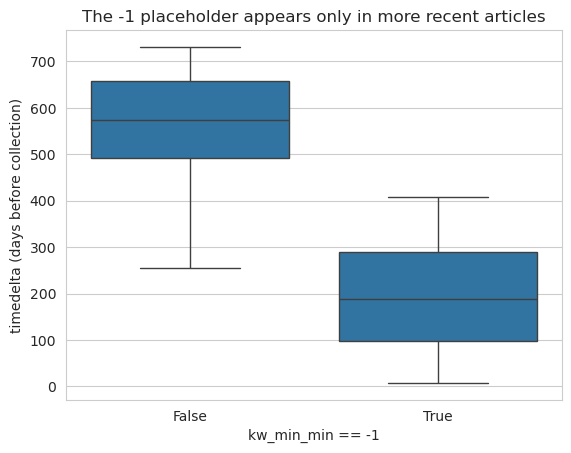

In [12]:
# Is the placeholder tied to when the article was published?
sns.boxplot(x=df['kw_min_min'] == -1, y=df['timedelta'])
plt.xlabel('kw_min_min == -1')
plt.ylabel('timedelta (days before collection)')
plt.title('The -1 placeholder appears only in more recent articles')
plt.show()

**What we found:**
- `kw_min_min` is −1 in **20,660 rows (58%)**. In practice it takes only three values (−1, 4 and 217), so it is close to a categorical code rather than a real measurement.
- The −1 rows are all **more recent** articles (`timedelta` below ~410 days, i.e. published from late 2013 onwards), while every older article has a non-negative value. The placeholder comes from a change in how keyword statistics were collected over time, not from the articles themselves.
- `kw_avg_min` (767) and `kw_min_avg` (6) have a few −1 values too.

**Action:** Clip all three columns at 0, so "unknown / no shares" becomes 0. Because `kw_min_min` mostly encodes time, Section 6 will probably show it is redundant with `timedelta`.

In [13]:
df[['kw_min_min', 'kw_avg_min', 'kw_min_avg']] = df[['kw_min_min', 'kw_avg_min', 'kw_min_avg']].clip(lower=0)

ratio_cols = ['n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens']
print('Negative kw values left:', (df[kw_cols] < 0).sum().sum())
print('Ratios outside [0, 1]  :', ((df[ratio_cols] < 0) | (df[ratio_cols] > 1)).sum().sum())

Negative kw values left: 0
Ratios outside [0, 1]  : 0


### 3.4 Articles with no text (`n_tokens_content == 0`)

**What:** Inspect the 1,061 articles with zero words: how many have images or videos, what their URLs look like, and how they are shared.

**Why:** These could be scrape failures, which would argue for dropping them, or genuine image/video posts, which would argue for keeping them.

In [14]:
no_text = df['n_tokens_content'] == 0
print('Articles with no text:', no_text.sum())
print('...with images or videos:', ((df.loc[no_text, 'num_imgs'] > 0) | (df.loc[no_text, 'num_videos'] > 0)).mean().round(3))
print('Median shares, no text vs rest:', df.loc[no_text, 'shares'].median(), 'vs', df.loc[~no_text, 'shares'].median())
df.loc[no_text, ['URL', 'num_imgs', 'num_videos', 'n_unique_tokens', 'average_token_length', 'shares']].head(8)

Articles with no text: 1061
...with images or videos: 0.63
Median shares, no text vs rest: 1600.0 vs 1400.0


,URL,num_imgs,num_videos,n_unique_tokens,average_token_length,shares
803,http://mashable.com/2013/01/23/actual-facebook...,10.0,0.0,0.0,0.0,2500
826,http://mashable.com/2013/01/23/fitness-gadget-...,0.0,0.0,0.0,0.0,1700
1010,http://mashable.com/2013/01/26/infographics-ma...,0.0,0.0,0.0,0.0,6800
1180,http://mashable.com/2013/01/29/social-tv-chart...,0.0,0.0,0.0,0.0,1000
1202,http://mashable.com/2013/01/30/blackberry-10-l...,0.0,0.0,0.0,0.0,1800
1216,http://mashable.com/2013/01/30/davos-social-me...,0.0,0.0,0.0,0.0,1200
1307,http://mashable.com/2013/01/31/nfl-super-bowl-...,0.0,0.0,0.0,0.0,2100
1337,http://mashable.com/2013/02/01/2012-internet-o...,12.0,0.0,0.0,0.0,1100


**What we found:**
- **63%** of the no-text articles contain images or videos, and the URLs describe visual posts: `infographics-marketing`, `social-tv-chart`, `liveblog`, `2012-internet-one-image`.
- They are shared slightly **more** than the rest (median 1,600 vs 1,400), so they do not behave like broken records.

**Action:** **Keep them**, on the assumption that these posts are purely images or videos. However, the text ratios (`n_unique_tokens`, `average_token_length`, …) are 0 only because there is no text to measure. A linear model would read that 0 as "very short words", so we add an `is_no_text` flag to separate the two cases.

In [15]:
df['is_no_text'] = (df['n_tokens_content'] == 0).astype(int)
df['is_no_text'].value_counts()

is_no_text
0    34619
1     1061
Name: count, dtype: int64

### 3.5 Feature engineering: publish date from `URL`

**What:** Every URL has the form `mashable.com/YYYY/MM/DD/slug/`. Extract the date into `pub_year` and `pub_month`. Also add `is_weekend` from `weekday`.

**Why:** The publish date allows a time-trend analysis (Section 5.3) and a seasonality feature (`pub_month`).

In [16]:
pub_date = pd.to_datetime(df['URL'].str.extract(r'/(\d{4}/\d{2}/\d{2})/')[0], format='%Y/%m/%d')
print('URLs without a date:', pub_date.isnull().sum())
print('Date range:', pub_date.min().date(), '->', pub_date.max().date())

df['pub_year'] = pub_date.dt.year
df['pub_month'] = pub_date.dt.month
df['is_weekend'] = df['weekday'].isin(['saturday', 'sunday']).astype(int)

# timedelta = days between publication and data collection, so it should mirror the date
print('Correlation of publish date with timedelta:',
      round(pub_date.map(pd.Timestamp.toordinal).corr(df['timedelta']), 4))

URLs without a date: 0
Date range: 2013-01-07 -> 2014-12-27
Correlation of publish date with timedelta: -1.0


**What we found:** All 35,680 URLs contain a date, from **2013-01-07 to 2014-12-27** (24 months). The publish date correlates **−1.000** with `timedelta`: `timedelta` is just the publish date counted backwards from the collection date.

**How this affects the next step:** `pub_year` (and the exact date) adds no information beyond `timedelta`. `pub_month` is new, because it captures the time of year rather than age.

### 3.6 Drop identifiers and final check

**What:** Drop `ID` and `URL`, now that the date has been extracted, and confirm the cleaned data is complete.

**Why:** An ID or URL is unique to each article and cannot generalise to new ones.

In [17]:
df = df.drop(columns=['ID', 'URL'])

assert df.isnull().sum().sum() == 0
assert (df[kw_cols] < 0).sum().sum() == 0
assert len(df) == 35680          # no rows dropped
print(df.shape)

(35680, 33)


**What we found:** The cleaned data has **35,680 rows** (none dropped) and **33 columns**: 30 originals − `ID` − `URL` + 5 new (`num_imgs_missing`, `is_no_text`, `pub_year`, `pub_month`, `is_weekend`). There are no missing values or negative share counts left.

## 4. Univariate analysis

### 4.1 Target: `shares`

**What:** Plot the distribution of `shares` on its raw scale and after a `log1p` transform (log(1 + x)).

**Why:** Most regression models, and especially linear regression with squared error, are pulled hard by a few extreme values. If the target is heavily skewed, predicting `log1p(shares)` usually gives a much better-behaved problem.

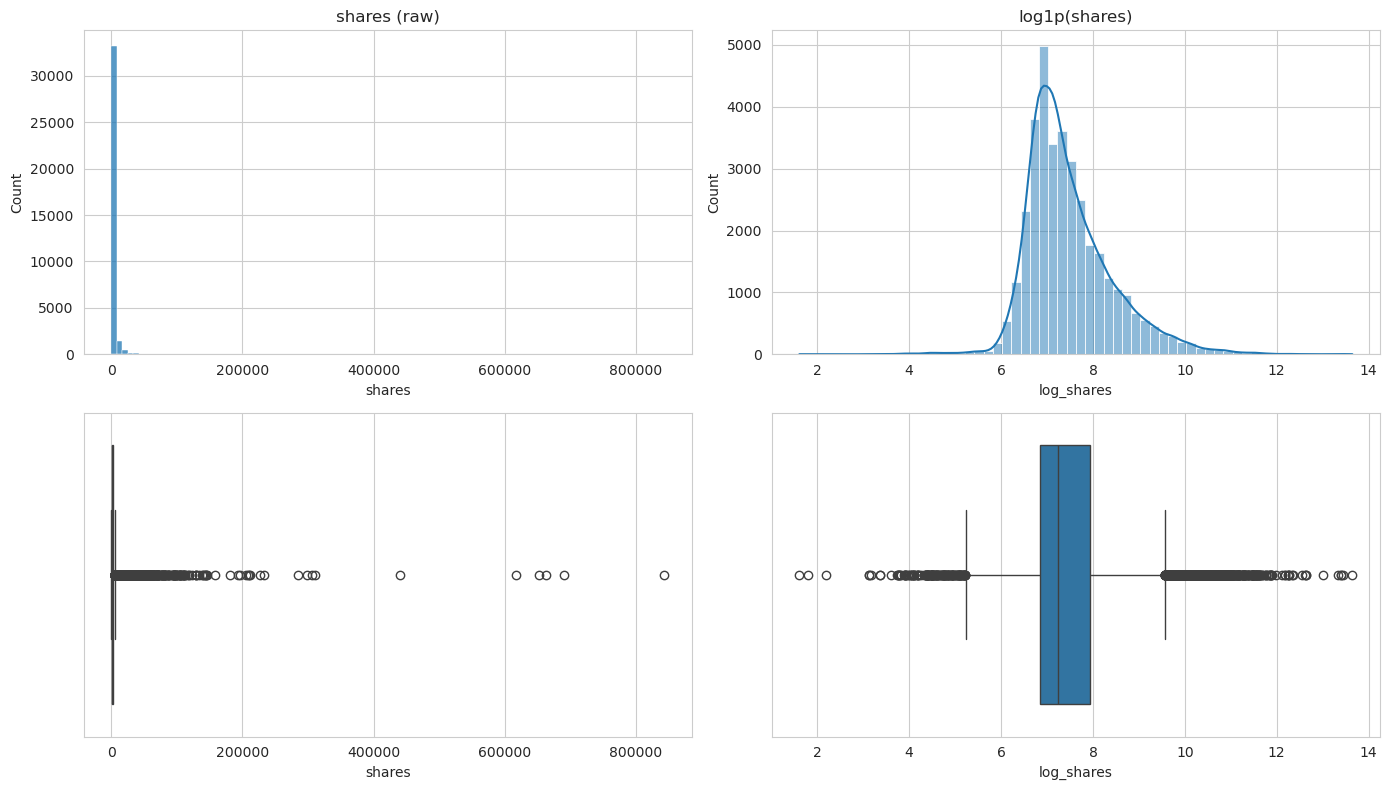

Skew raw : 34.41
Skew log : 1.04


0.500      1400.0
0.750      2800.0
0.900      6200.0
0.990     32000.0
0.999    112532.1
Name: shares, dtype: float64

In [18]:
df['log_shares'] = np.log1p(df['shares'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sns.histplot(df['shares'], bins=100, ax=axes[0, 0])
axes[0, 0].set_title('shares (raw)')
sns.boxplot(x=df['shares'], ax=axes[1, 0])
sns.histplot(df['log_shares'], bins=60, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('log1p(shares)')
sns.boxplot(x=df['log_shares'], ax=axes[1, 1])
plt.tight_layout()
plt.show()

print('Skew raw :', round(df['shares'].skew(), 2))
print('Skew log :', round(df['log_shares'].skew(), 2))
df['shares'].quantile([0.5, 0.75, 0.9, 0.99, 0.999])

In [19]:
q1, q3 = df['shares'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f'IQR upper fence: {upper:.0f} shares -> {(df["shares"] > upper).sum()} articles above it '
      f'({(df["shares"] > upper).mean():.1%})')

IQR upper fence: 5581 shares -> 4080 articles above it (11.4%)


**What we found:**
- Raw `shares` has a skew of **~34**. Half of the articles get ≤ 1,400 shares, 90% get ≤ 6,200, and a long tail of viral articles reaches 843,300.
- About **11%** of articles (4,080) lie above the IQR fence of 5,581. These are real viral articles, not data errors, so we **do not remove them**.
- After `log1p` the distribution is close to bell-shaped (skew ≈ **1.0**).

**How this affects the modelling:** Train on **`log1p(shares)`** and convert predictions back with `expm1`. Otherwise the loss will be dominated by a few hundred viral articles. All the bivariate and correlation analysis below uses `log_shares`.

### 4.2 Numeric features

**What:** Plot a histogram of every numeric feature and rank the features by skewness.

**Why:** Heavily skewed features have the same problem as the target. They are candidates for a `log1p` transform, especially for linear models. Near-constant features carry little information.

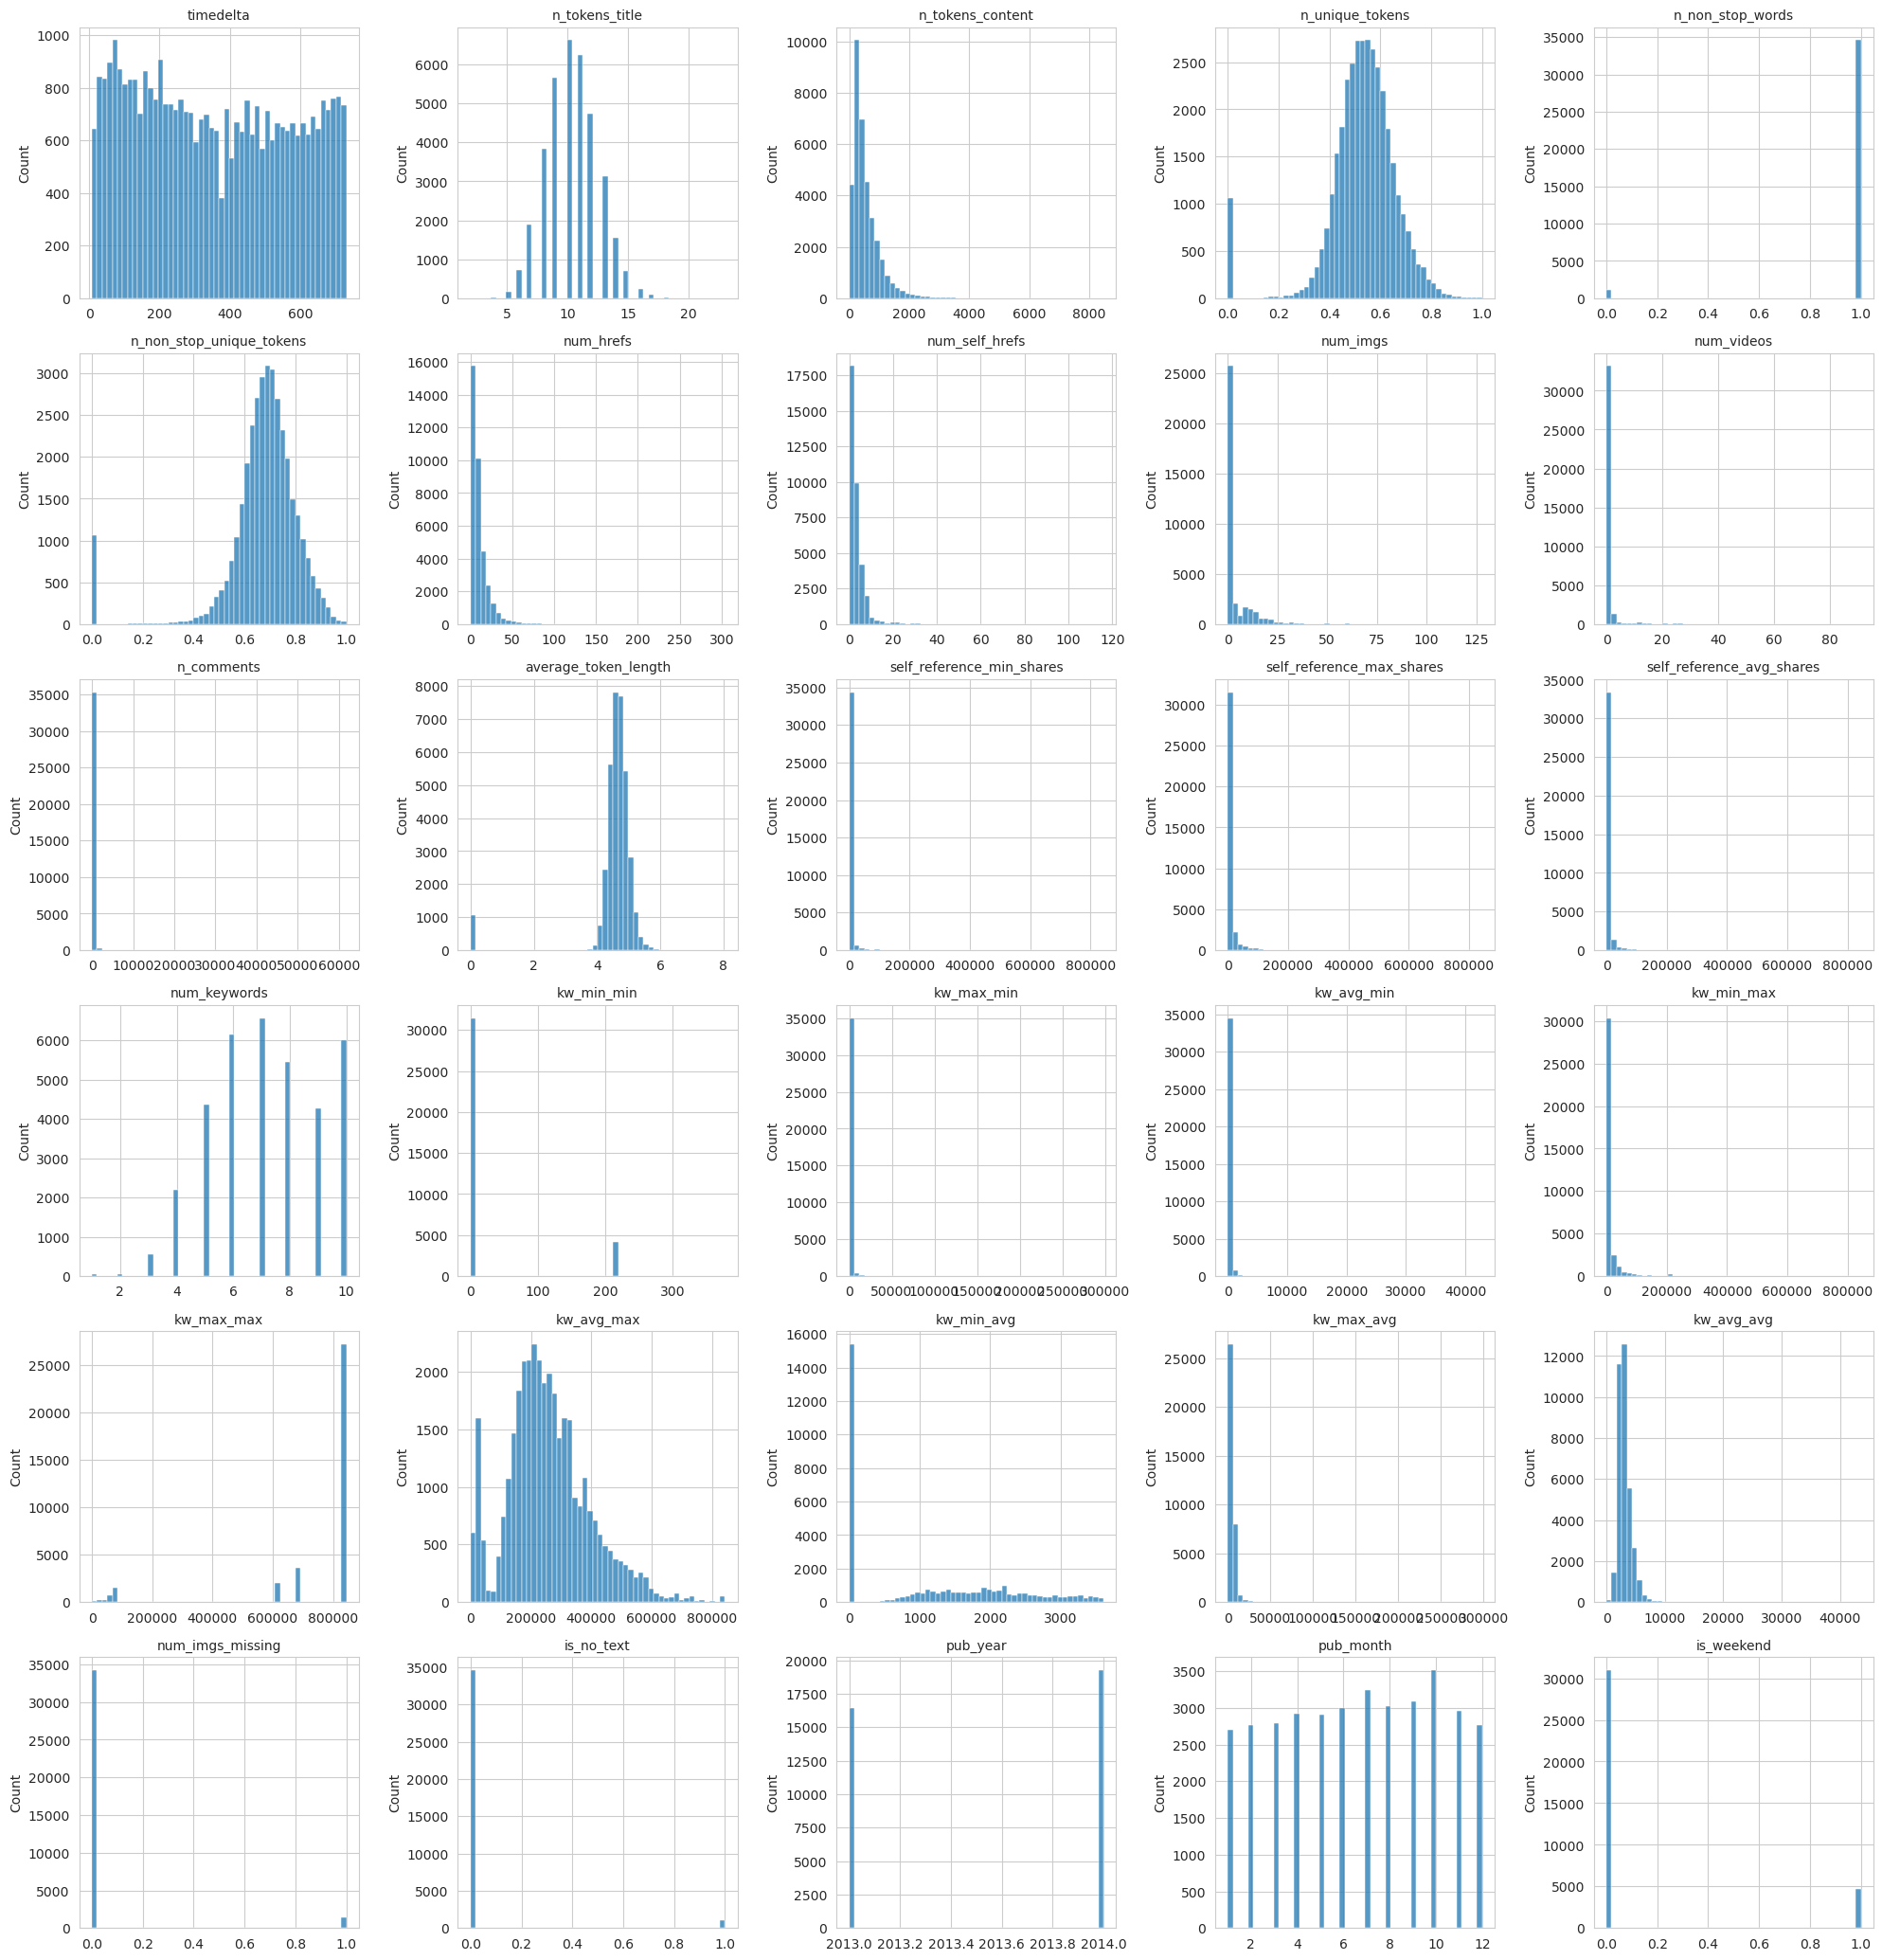

In [20]:
feature_cols = df.select_dtypes('number').columns.drop(['shares', 'log_shares'])

fig, axes = plt.subplots(7, 5, figsize=(20, 24))
for ax, col in zip(axes.flat, feature_cols):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
for ax in axes.flat[len(feature_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

In [21]:
skew = df[feature_cols].skew().sort_values(ascending=False).round(2)
skew.to_frame('skew')

,skew
n_comments,67.36
kw_max_min,37.48
kw_avg_min,33.10
self_reference_min_shares,26.25
self_reference_avg_shares,18.03
kw_max_avg,17.07
self_reference_max_shares,14.04
kw_min_max,10.45
num_videos,9.21
kw_avg_avg,5.89


In [22]:
print('n_non_stop_words values:', df['n_non_stop_words'].round(3).value_counts().to_dict())
print('kw_max_max top values  :', df['kw_max_max'].value_counts(normalize=True).head(3).round(3).to_dict())

n_non_stop_words values: {1.0: 34619, 0.0: 1061}
kw_max_max top values  : {843300.0: 0.762, 690400.0: 0.1, 617900.0: 0.058}


**What we found:**
- **Very heavy right tails** (skew > 5): `n_comments` (67), `kw_max_min`, `kw_avg_min`, the three `self_reference_*` columns, `kw_max_avg`, `kw_min_max`, `num_videos`, `kw_avg_avg` and `num_self_hrefs`. These are counts or share totals, and most values are small with a few huge ones.
- **`n_non_stop_words` is effectively binary:** it is 1.0 for every article with text and 0 for the 1,061 no-text articles. It is a copy of `is_no_text`.
- **`kw_max_max` is almost constant:** 76% of rows share the value 843,300, which is the maximum share count in the dataset.
- The text ratios (`n_unique_tokens`, `average_token_length`) are roughly bell-shaped apart from the spike at 0 from the no-text articles.

**How this affects the modelling:** Apply `log1p` to the heavily skewed count and share features for linear models; tree-based models do not need it. Drop `n_non_stop_words`, which duplicates `is_no_text`.

### 4.3 Categorical features

**What:** Count the articles in each level of `weekday` and `data_channel`.

**Why:** We check for spelling variants and very rare levels before one-hot encoding.

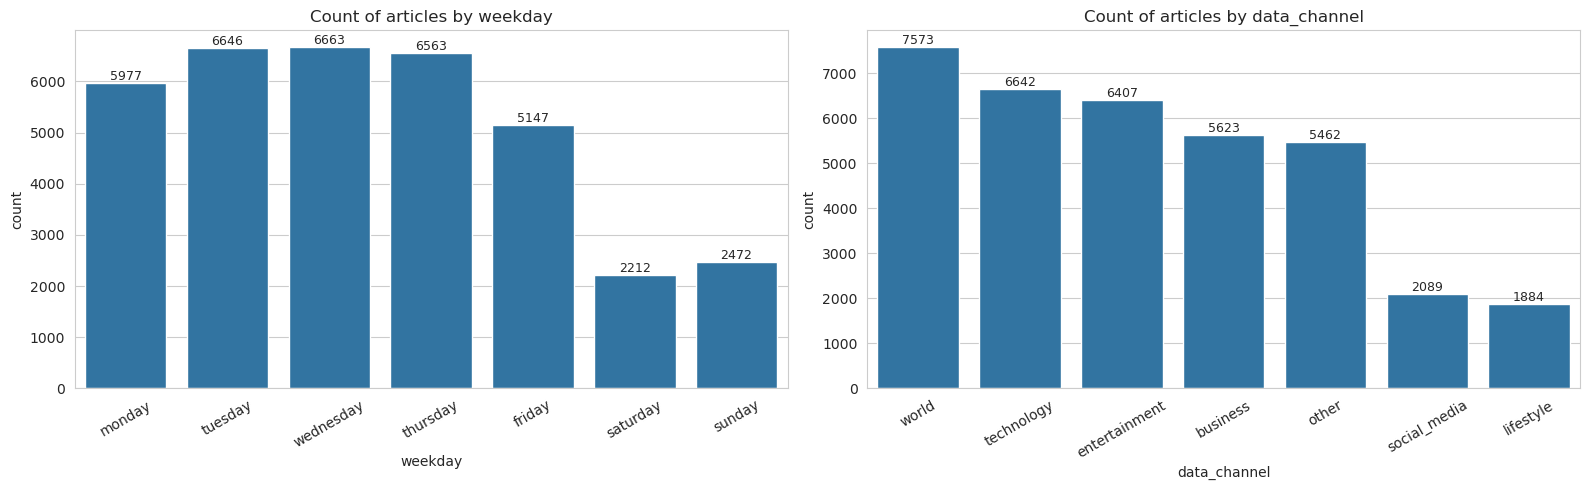

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
day_order = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']
for ax, col, order in [(axes[0], 'weekday', day_order),
                       (axes[1], 'data_channel', df['data_channel'].value_counts().index)]:
    cp = sns.countplot(x=col, data=df, order=order, ax=ax)
    ax.set_title(f'Count of articles by {col}')
    ax.tick_params(axis='x', rotation=30)
    for p in cp.patches:
        cp.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

**What we found:**
- The labels are clean: 7 weekdays and 7 channels (including the new `other`), with no spelling variants.
- Publishing volume is concentrated on **weekdays** (~5–6.7k each). Saturday and Sunday have far fewer articles (~2.2–2.5k).
- `world`, `technology` and `entertainment` are the largest channels; `social_media` and `lifestyle` are the smallest (~2k each), which is still plenty of rows per level.

**How this affects the modelling:** Both columns can be **one-hot encoded** directly. No levels need to be merged.

## 5. Bivariate analysis: feature vs `log_shares`

### 5.1 Categorical features

**What:** Compare the distribution of `log_shares` across the levels of `weekday`, `data_channel` and `is_weekend`.

**Why:** If the medians differ clearly between levels, the feature helps to predict shares.

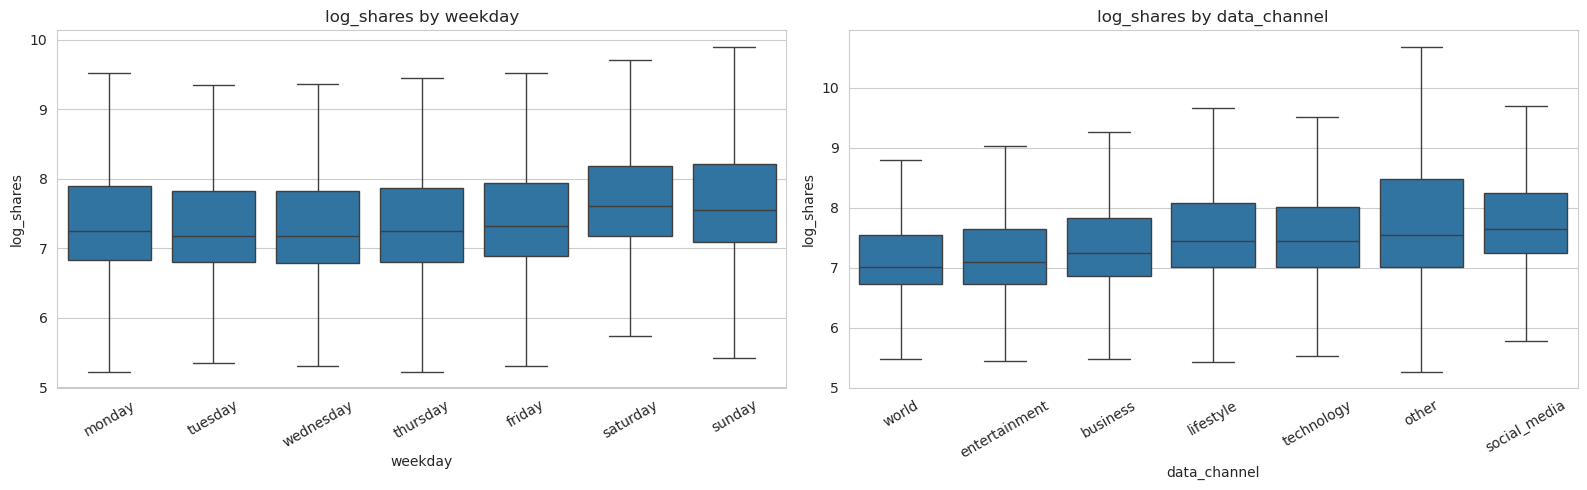

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(x='weekday', y='log_shares', data=df, order=day_order, ax=axes[0], showfliers=False)
channel_order = df.groupby('data_channel')['log_shares'].median().sort_values().index
sns.boxplot(x='data_channel', y='log_shares', data=df, order=channel_order, ax=axes[1], showfliers=False)
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
axes[0].set_title('log_shares by weekday')
axes[1].set_title('log_shares by data_channel')
plt.tight_layout()
plt.show()

In [25]:
for col in ['weekday', 'data_channel', 'is_weekend']:
    print(df.groupby(col)['shares'].agg(['count', 'median', 'mean']).round(0).sort_values('median'), '\n')

           count  median    mean
weekday                         
wednesday   6663  1300.0  3275.0
tuesday     6646  1300.0  3220.0
monday      5977  1400.0  3653.0
thursday    6563  1400.0  3176.0
friday      5147  1500.0  3314.0
sunday      2472  1900.0  3732.0
saturday    2212  2000.0  4158.0 

               count  median    mean
data_channel                        
world           7573  1100.0  2304.0
entertainment   6407  1200.0  2956.0
business        5623  1400.0  3106.0
lifestyle       1884  1700.0  3680.0
technology      6642  1700.0  3066.0
other           5462  1900.0  5993.0
social_media    2089  2100.0  3590.0 

            count  median    mean
is_weekend                       
0           30996  1400.0  3322.0
1            4684  2000.0  3933.0 



**What we found:**
- **Weekend articles are shared more:** the median is 2,000 on Saturday and 1,900 on Sunday, against 1,300–1,500 on weekdays. There are fewer weekend articles, so each one faces less competition. `is_weekend` captures most of the weekday effect on its own.
- **The channel matters:** `social_media` (median 2,100) and `other` (1,900) are shared most, while `world` (1,100) and `entertainment` (1,200) are shared least. That puts the blog pages in `other` among the best performers, which confirms that a separate level was the right choice.

**How this affects the modelling:** Keep `data_channel` (one-hot) and `is_weekend`. `weekday` adds little beyond `is_weekend`, but it is cheap to keep it one-hot for tree models.

### 5.2 Numeric features

**What:** For the strongest numeric candidates, bin the feature into deciles and plot the median `log_shares` per bin.

**Why:** With 35k noisy points, a scatter plot is an unreadable cloud. A binned median line shows the shape of the relationship (rising, flat or curved) much more clearly.

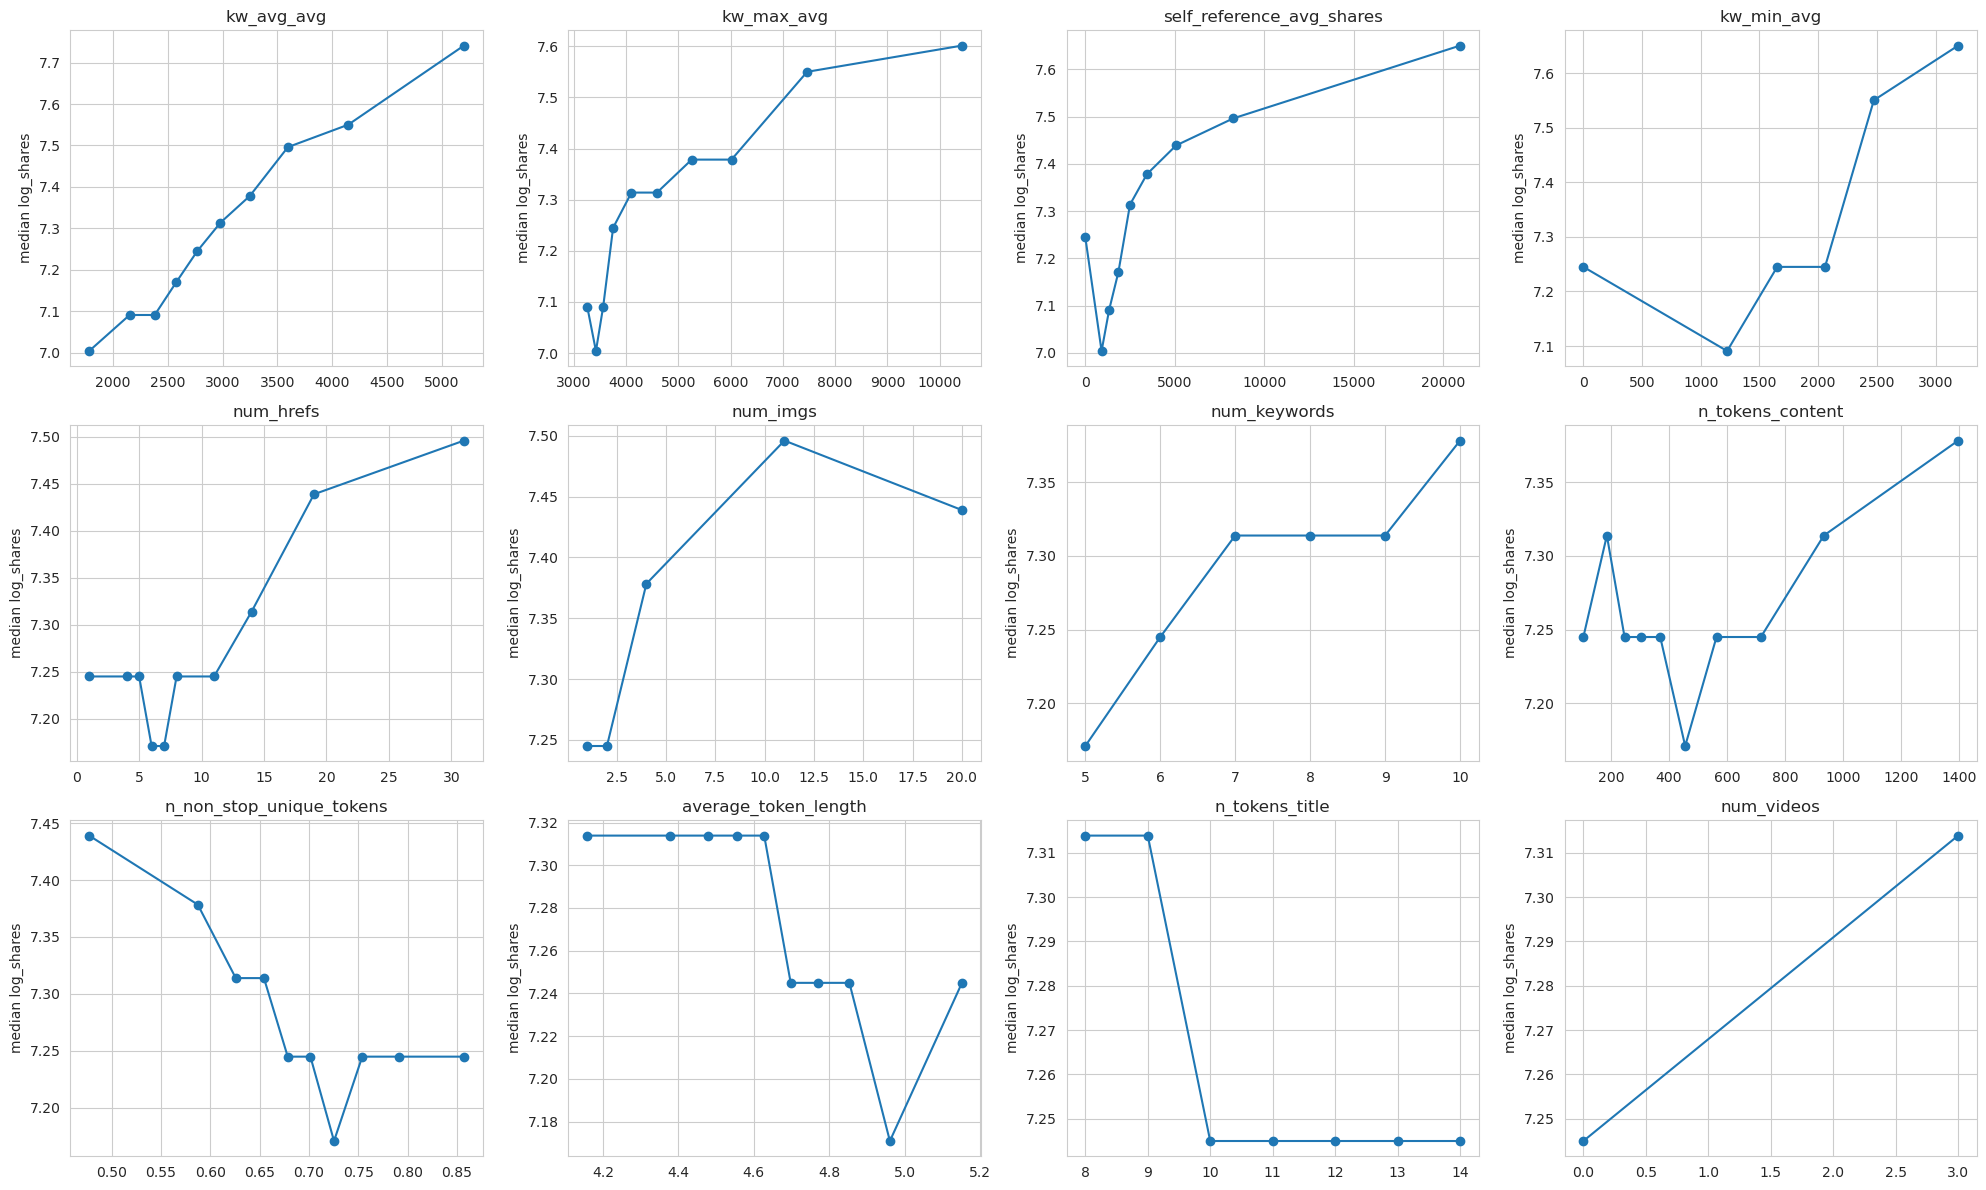

In [26]:
candidates = ['kw_avg_avg', 'kw_max_avg', 'self_reference_avg_shares', 'kw_min_avg',
              'num_hrefs', 'num_imgs', 'num_keywords', 'n_tokens_content',
              'n_non_stop_unique_tokens', 'average_token_length', 'n_tokens_title', 'num_videos']

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, candidates):
    bins = pd.qcut(df[col], q=10, duplicates='drop')
    binned = df.groupby(bins, observed=True).agg(x=(col, 'median'), y=('log_shares', 'median'))
    ax.plot(binned['x'], binned['y'], marker='o')
    ax.set_title(col)
    ax.set_ylabel('median log_shares')
plt.tight_layout()
plt.show()

**What we found:**
- **`kw_avg_avg` rises steadily across its whole range**, from a median log_shares of ~7.0 to ~7.75 (roughly 1,100 → 2,300 shares). Articles whose keywords did well historically are shared more. This is the clearest numeric signal.
- **`kw_max_avg` and `self_reference_avg_shares` also rise**, but non-linearly: the gain is steep at first and then levels off. `self_reference_avg_shares` has a bump at 0 (articles with no self-links). `kw_min_avg` dips before rising.
- `num_hrefs` (above ~10 links), `num_imgs` (up to ~10 images) and `num_keywords` have a mild positive trend.
- `n_non_stop_unique_tokens` **falls**: articles with more varied vocabulary are shared slightly less. `average_token_length` is flat and then drops for long words (> ~4.7 characters).
- `n_tokens_content` rises only for long articles (> ~900 words). `n_tokens_title` and `num_videos` move by < 0.1 on the log scale, which is practically flat.

**How this affects the modelling:** Signals are weak and partly non-linear, which favours **tree-based models** (random forest or gradient boosting) over plain linear regression.

### 5.3 Time trend

**What:** Plot the median and mean `log_shares` for each publish month across the two years, together with the number of articles per month. Also compare `log_shares` across calendar months and across `timedelta` bands.

**Why:** If sharing behaviour drifts over time, a random train/test split may hide that drift. We also need to check whether recent articles (small `timedelta`) have fewer shares simply because they had less time to collect them.

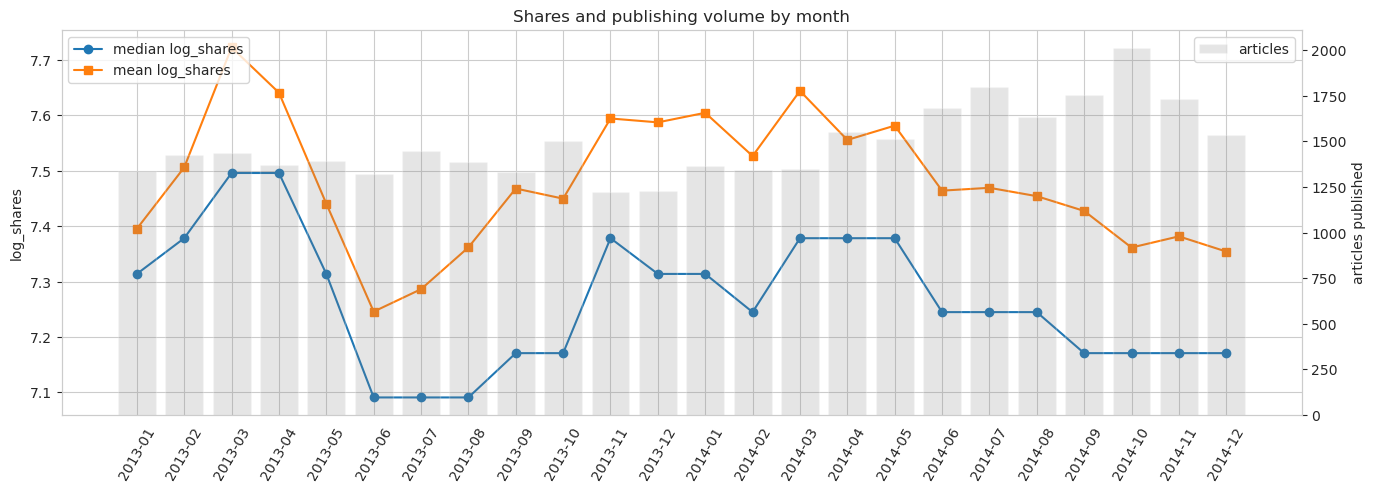

In [27]:
monthly = (df.groupby(['pub_year', 'pub_month'])
             .agg(median_log=('log_shares', 'median'), mean_log=('log_shares', 'mean'), n=('log_shares', 'size'))
             .reset_index())
monthly['period'] = monthly['pub_year'].astype(str) + '-' + monthly['pub_month'].astype(str).str.zfill(2)

fig, ax1 = plt.subplots(figsize=(16, 5))
ax1.plot(monthly['period'], monthly['median_log'], marker='o', label='median log_shares')
ax1.plot(monthly['period'], monthly['mean_log'], marker='s', label='mean log_shares')
ax1.set_ylabel('log_shares')
ax1.tick_params(axis='x', rotation=60)
ax2 = ax1.twinx()
ax2.bar(monthly['period'], monthly['n'], alpha=0.2, color='grey', label='articles')
ax2.set_ylabel('articles published')
ax2.grid(False)
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.title('Shares and publishing volume by month')
plt.show()

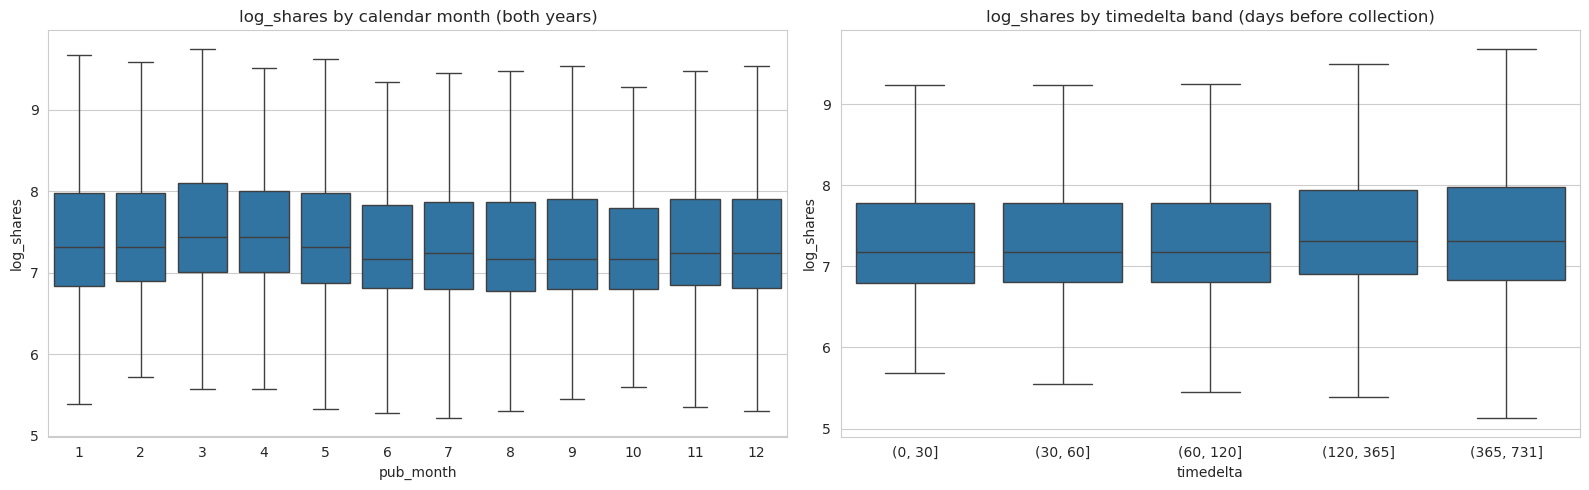

timedelta
(0, 30]       1300.0
(30, 60]      1300.0
(60, 120]     1300.0
(120, 365]    1500.0
(365, 731]    1500.0
Name: shares, dtype: float64

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(x='pub_month', y='log_shares', data=df, ax=axes[0], showfliers=False)
axes[0].set_title('log_shares by calendar month (both years)')

age_bands = pd.cut(df['timedelta'], bins=[0, 30, 60, 120, 365, 731])
sns.boxplot(x=age_bands, y=df['log_shares'], ax=axes[1], showfliers=False)
axes[1].set_title('log_shares by timedelta band (days before collection)')
plt.tight_layout()
plt.show()

df.groupby(age_bands, observed=True)['shares'].median()

**What we found:**
- **Publishing volume grew** from ~1.3–1.4k articles a month in 2013 to 1.5–2k a month in late 2014.
- **No steady trend, but clear swings.** The median peaks in spring 2013 (~1,800 shares), drops sharply in summer 2013 (~1,200), recovers from November 2013 to May 2014 (~1,500–1,600), then falls again through the second half of 2014 (~1,300) as volume rises. The last decline coincides with more articles competing for attention.
- **Mild seasonality:** in both years spring is strong and summer is weak. March–April are the strongest calendar months (median 1,700) and June–October the weakest (1,300).
- **Recent articles are not obviously penalised.** Articles published 0–120 days before collection have a median of 1,300 against 1,500 for older ones, a small gap. Most sharing appears to happen soon after publication.

**How this affects the modelling:** Keep `pub_month` for seasonality and `timedelta` for the slow drift and age. Drop `pub_year`, which is redundant with `timedelta`. The drift is small enough that a random split is acceptable, but a time-ordered hold-out would be a stricter test.

### 5.4 Leakage check: `n_comments`

**What:** Look at how `n_comments` relates to shares.

**Why:** Reader comments, like shares, build up **after** an article is published. If we want to predict shares *at publication time*, `n_comments` would not be available yet. Using it would **leak** future information and make the model look better than it really is.

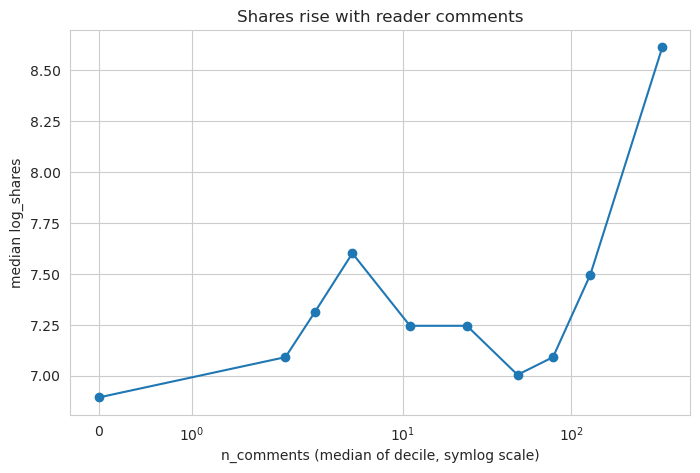

Spearman(n_comments, log_shares): 0.362


In [29]:
bins = pd.qcut(df['n_comments'], q=10, duplicates='drop')
binned = df.groupby(bins, observed=True).agg(x=('n_comments', 'median'), y=('log_shares', 'median'))
plt.figure(figsize=(8, 5))
plt.plot(binned['x'], binned['y'], marker='o')
plt.xscale('symlog')
plt.xlabel('n_comments (median of decile, symlog scale)')
plt.ylabel('median log_shares')
plt.title('Shares rise with reader comments')
plt.show()

print('Spearman(n_comments, log_shares):', round(df['n_comments'].corr(df['log_shares'], method='spearman'), 3))

**What we found:** `n_comments` has the **strongest relationship with shares of any feature** (Spearman ≈ 0.36), and shares rise steadily with comments. That strength comes from both being measures of the same thing: how popular the article turned out to be.

**Recommendation:** **Exclude `n_comments`** if the model is meant to predict shares before or at publication, which is the usual use case. If the goal is only to explain shares after the fact, it could be kept. Either way, the decision should be stated explicitly in the model report.

## 6. Correlation analysis

### 6.1 Correlation of each feature with the target

**What:** Compute the Pearson and Spearman correlation of every numeric feature with `log_shares` and rank them.

**Why:** Pearson measures **linear** association and is sensitive to outliers. Spearman works on ranks, so it captures any **monotonic** relationship and is robust to the heavy tails found in Section 4. Spearman is the main measure here.

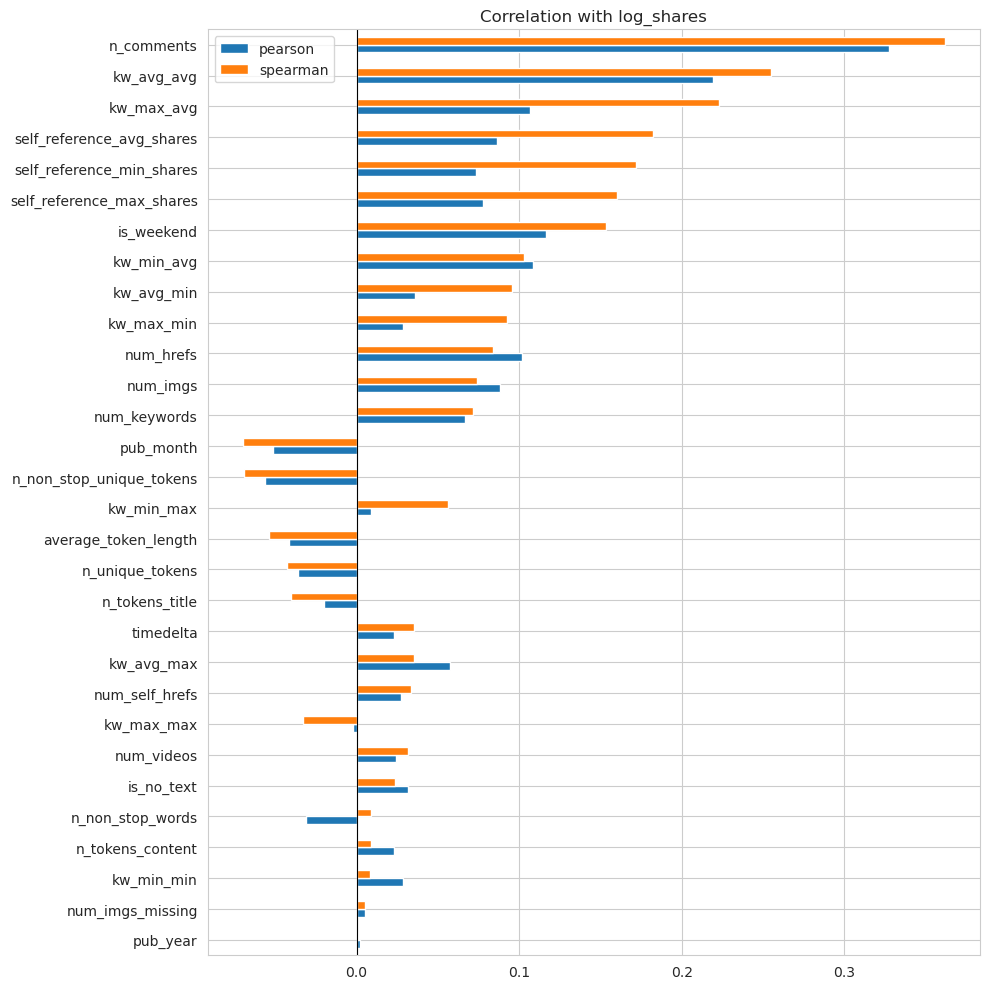

,pearson,spearman
n_comments,0.327,0.362
kw_avg_avg,0.219,0.255
kw_max_avg,0.107,0.223
self_reference_avg_shares,0.087,0.182
self_reference_min_shares,0.073,0.172
self_reference_max_shares,0.078,0.160
is_weekend,0.116,0.153
kw_min_avg,0.108,0.103
kw_avg_min,0.036,0.095
kw_max_min,0.029,0.092


In [30]:
target_corr = pd.DataFrame({
    'pearson': df[feature_cols].corrwith(df['log_shares']),
    'spearman': df[feature_cols].corrwith(df['log_shares'], method='spearman'),
}).sort_values('spearman', key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 10))
target_corr.iloc[::-1].plot.barh(ax=ax)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Correlation with log_shares')
plt.tight_layout()
plt.show()

target_corr.round(3)

**What we found:**
- **All correlations are weak.** Apart from `n_comments` (≈ 0.36, excluded as leakage), the strongest is `kw_avg_avg` (ρ ≈ **0.26**), followed by `kw_max_avg` (0.22), the three `self_reference_*` columns (0.16–0.18) and `is_weekend` (0.15). Article popularity is hard to predict from these features alone, so we should expect a modest R².
- **The self-reference features matter more than expected:** `self_reference_avg_shares` is the fourth-strongest feature, so the group stays (as one column; see 6.2).
- **Near-zero correlations** (|ρ| < 0.02): `pub_year`, `num_imgs_missing`, `kw_min_min`, `n_tokens_content` and `n_non_stop_words`.
- Spearman is clearly higher than Pearson for the skewed features (for example `kw_max_avg` 0.22 vs 0.11). Their relationship is monotonic but not linear, which again points to `log1p` transforms or tree models.

### 6.2 Redundancy between features

**What:** Compute the feature-to-feature Spearman correlation matrix, then list every pair with |ρ| > 0.8.

**Why:** Highly correlated features carry the same information. They inflate the coefficient variance in linear models and split importance in tree models. From each redundant pair we keep the feature with the stronger link to the target.

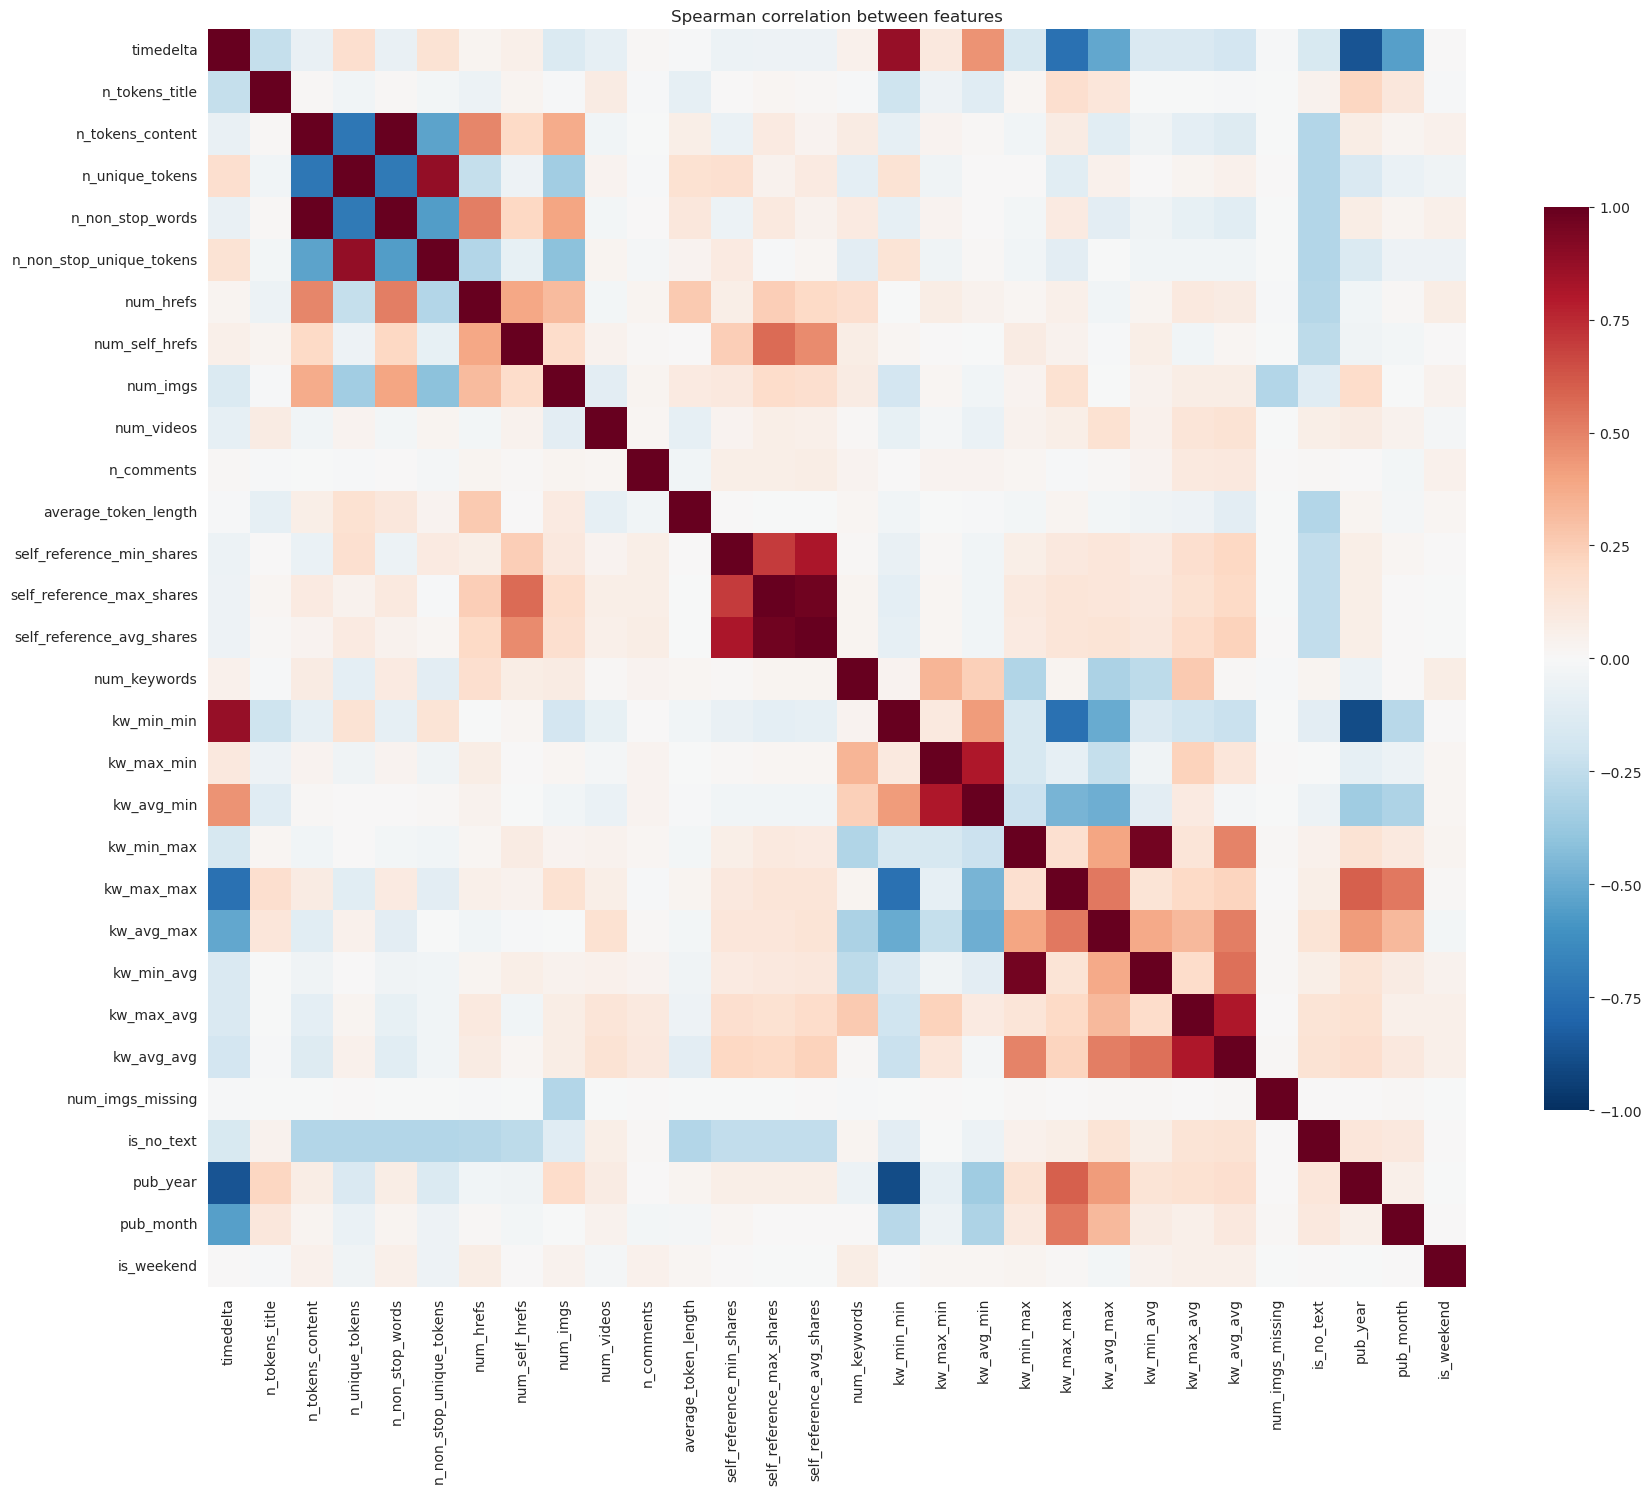

In [31]:
spearman = df[feature_cols].corr(method='spearman')

plt.figure(figsize=(18, 15))
sns.heatmap(spearman, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={'shrink': 0.7})
plt.title('Spearman correlation between features')
plt.tight_layout()
plt.show()

In [32]:
pairs = []
cols = spearman.columns
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        if abs(spearman.loc[a, b]) > 0.8:
            keep = a if abs(target_corr.loc[a, 'spearman']) >= abs(target_corr.loc[b, 'spearman']) else b
            pairs.append({'feature_a': a, 'feature_b': b, 'rho': round(spearman.loc[a, b], 3),
                          'rho_a_target': round(target_corr.loc[a, 'spearman'], 3),
                          'rho_b_target': round(target_corr.loc[b, 'spearman'], 3),
                          'keep': keep})
pd.DataFrame(pairs).sort_values('rho', key=abs, ascending=False)

,feature_a,feature_b,rho,rho_a_target,rho_b_target,keep
2,n_tokens_content,n_non_stop_words,0.995,0.009,0.009,n_non_stop_words
5,self_reference_max_shares,self_reference_avg_shares,0.975,0.160,0.182,self_reference_avg_shares
8,kw_min_max,kw_min_avg,0.961,0.056,0.103,kw_min_avg
6,kw_min_min,pub_year,-0.892,0.008,0.001,kw_min_min
3,n_unique_tokens,n_non_stop_unique_tokens,0.881,-0.043,-0.069,n_non_stop_unique_tokens
0,timedelta,kw_min_min,0.874,0.035,0.008,timedelta
1,timedelta,pub_year,-0.863,0.035,0.001,timedelta
4,self_reference_min_shares,self_reference_avg_shares,0.815,0.172,0.182,self_reference_avg_shares
7,kw_max_min,kw_avg_min,0.807,0.092,0.095,kw_avg_min
9,kw_max_avg,kw_avg_avg,0.806,0.223,0.255,kw_avg_avg


**What we found (10 pairs with |ρ| > 0.8):** The `keep` column above is a mechanical rule (higher |ρ| with the target wins). The table below applies judgement where the rule ties (`n_tokens_content` / `n_non_stop_words`, both 0.009) or where three features form one group.

| Redundant group | ρ | Keep | Drop | Reason |
|---|---|---|---|---|
| `n_tokens_content` / `n_non_stop_words` | 0.995 | `n_tokens_content` | `n_non_stop_words` | `n_non_stop_words` is just an "has text" indicator, already in `is_no_text` |
| `self_reference_max` / `_avg` / `_min_shares` | 0.82–0.98 | `self_reference_avg_shares` | `_min`, `_max` | `avg` has the strongest target link (0.18) |
| `kw_min_max` / `kw_min_avg` | 0.96 | `kw_min_avg` | `kw_min_max` | 0.10 vs 0.06 |
| `n_unique_tokens` / `n_non_stop_unique_tokens` | 0.88 | `n_non_stop_unique_tokens` | `n_unique_tokens` | −0.07 vs −0.04 |
| `timedelta` / `pub_year` / `kw_min_min` | 0.86–0.89 | `timedelta` | `pub_year`, `kw_min_min` | All three encode age; `kw_min_min` and `pub_year` have ~0 target link |
| `kw_max_min` / `kw_avg_min` | 0.81 | `kw_avg_min` | `kw_max_min` | 0.095 vs 0.092 (near tie) |
| `kw_max_avg` / `kw_avg_avg` | 0.81 | `kw_avg_avg` | `kw_max_avg` | 0.26 vs 0.22 |

`kw_min_min` confirms the suspicion from Section 3.3: its −1/4/217 codes track collection time, not keyword performance.

### 6.3 Categorical levels vs target

**What:** One-hot encode `weekday` and `data_channel` and correlate each level with `log_shares`.

**Why:** This puts the categorical levels on the same scale as the numeric correlations in 6.1.

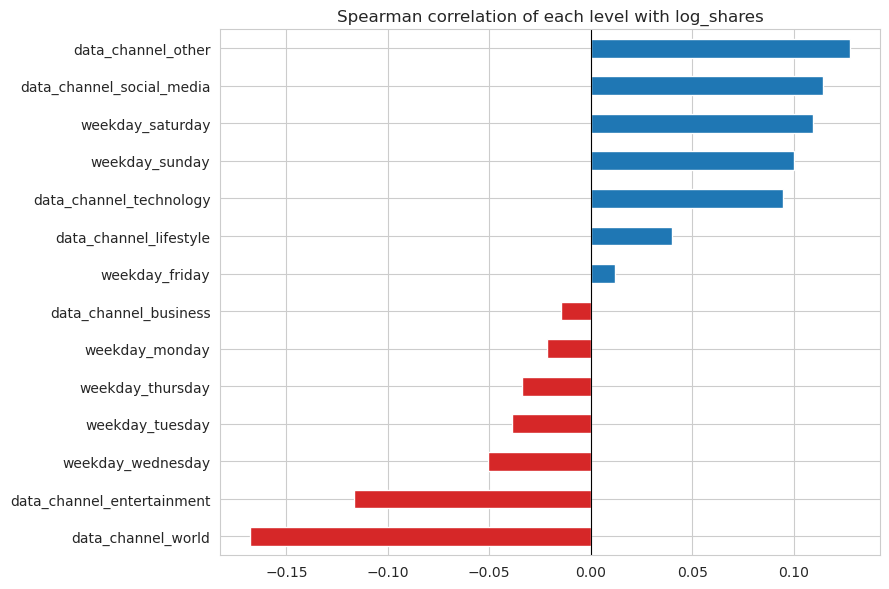

data_channel_world           -0.168
data_channel_entertainment   -0.117
weekday_wednesday            -0.050
weekday_tuesday              -0.039
weekday_thursday             -0.034
weekday_monday               -0.022
data_channel_business        -0.015
weekday_friday                0.012
data_channel_lifestyle        0.040
data_channel_technology       0.095
weekday_sunday                0.100
weekday_saturday              0.109
data_channel_social_media     0.114
data_channel_other            0.128
dtype: float64

In [33]:
dummies = pd.get_dummies(df[['weekday', 'data_channel']], dtype=int)
level_corr = dummies.corrwith(df['log_shares'], method='spearman').sort_values()

plt.figure(figsize=(9, 6))
level_corr.plot.barh(color=np.where(level_corr > 0, 'tab:blue', 'tab:red'))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Spearman correlation of each level with log_shares')
plt.tight_layout()
plt.show()

level_corr.round(3)

**What we found:** `data_channel_world` (ρ ≈ −0.17) and `data_channel_entertainment` (−0.12) pull shares down, about as strongly as the `self_reference_*` features push them up. `other` (0.13), `social_media` (0.11), Saturday/Sunday (~0.10) and `technology` (0.10) push shares up. After `kw_avg_avg`, channel is one of the most informative inputs.

### 6.4 Keyword features: which of the nine `kw_*` columns to keep?

**What:** The nine `kw_*` columns form a 3 × 3 grid. The **suffix** picks a keyword: the worst (`_min`), best (`_max`) or median (`_avg`) performing keyword of the article. The **prefix** summarises past articles that used that keyword: their minimum, maximum or average shares. So `kw_avg_min` = *the average shares of articles that used this article's worst keyword*.

We compare the grid three ways: (1) each cell's correlation with the target, (2) how redundant the three `kw_avg_*` columns are with each other, and (3) how much predictive power different subsets carry, using a quick 5-fold cross-validated gradient-boosting model on the keyword columns alone.

**Why:** We want to keep the **average column** (`kw_avg_min`, `kw_avg_max`, `kw_avg_avg`): for each keyword, the average summarises the min and max into one number. This section checks that the choice does not throw away signal.

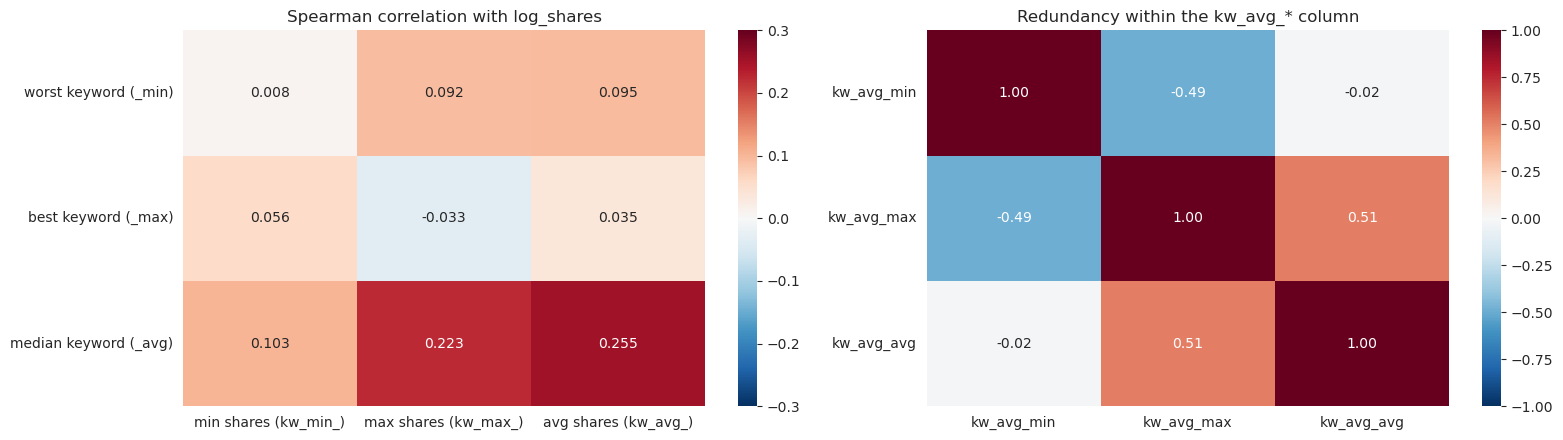

In [34]:
stats = ['min', 'max', 'avg']   # prefix: statistic over past articles
kw_grid = pd.DataFrame(
    [[target_corr.loc[f'kw_{s}_{k}', 'spearman'] for s in stats] for k in stats],
    index=['worst keyword (_min)', 'best keyword (_max)', 'median keyword (_avg)'],
    columns=[f'{s} shares (kw_{s}_)' for s in stats])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.heatmap(kw_grid, annot=True, fmt='.3f', cmap='RdBu_r', center=0, vmin=-0.3, vmax=0.3, ax=axes[0])
axes[0].set_title('Spearman correlation with log_shares')

kw_avg_cols = ['kw_avg_min', 'kw_avg_max', 'kw_avg_avg']
sns.heatmap(df[kw_avg_cols].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Redundancy within the kw_avg_* column')
axes[0].tick_params(axis='x', rotation=0)
axes[1].tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

In [35]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score

kw_subsets = {
    'kw_avg_avg only': ['kw_avg_avg'],
    'avg column: kw_avg_min / _max / _avg': kw_avg_cols,
    'avg row: kw_min_avg / kw_max_avg / kw_avg_avg': ['kw_min_avg', 'kw_max_avg', 'kw_avg_avg'],
    'all nine kw_*': kw_cols,
}
scores = {name: cross_val_score(HistGradientBoostingRegressor(random_state=0), df[cols], df['log_shares'],
                                cv=5, scoring='r2').mean()
          for name, cols in kw_subsets.items()}
pd.Series(scores, name='CV R² (keyword features only)').round(4).to_frame()

,CV R² (keyword features only)
kw_avg_avg only,0.0494
avg column: kw_avg_min / _max / _avg,0.0451
avg row: kw_min_avg / kw_max_avg / kw_avg_avg,0.0512
all nine kw_*,0.0513


**What we found:**
- **The signal sits in the `_avg` row** (the median keyword): `kw_avg_avg` (0.26), `kw_max_avg` (0.22) and `kw_min_avg` (0.10). The `_max` row (best keyword) is almost useless: `kw_max_max` (−0.03) is a near-constant and `kw_min_max` (0.06) is 0 for 43% of articles.
- **The `kw_avg_*` column is not redundant.** Its three members correlate at most 0.51 (`kw_avg_max` with `kw_avg_avg`), and `kw_avg_min` with `kw_avg_avg` is ≈ 0, so each one adds different information. Correlation is not a reason to drop any of them.
- **Predictive power is similar across the subsets** (CV R² ≈ 0.045–0.051 using keywords alone). The avg column scores slightly below `kw_avg_avg` alone and the avg row, but the gaps (< 0.01) are within fold-to-fold noise.

**Decision:** Keep the **avg column** (`kw_avg_min`, `kw_avg_max`, `kw_avg_avg`) and drop the other six `kw_*` columns. It is a consistent, interpretable summary (one average per keyword tier) that loses almost nothing. If the model later needs more signal, adding back `kw_max_avg` (ρ 0.22) is the first thing to try.

## 7. Summary: implications for the regression model

### Data cleaning performed

| Issue | Rows affected | Fix |
|---|---|---|
| Duplicates (full / ID / URL / ignoring ID) | 0 | None needed |
| `data_channel` missing (blog pages) | 5,462 | New level `'other'` |
| `num_videos` missing | 16,755 | Fill 0 |
| `num_imgs` missing | 1,419 | Fill 0 + `num_imgs_missing` flag |
| `num_hrefs`, `num_self_hrefs`, `self_reference_*` missing (same rows) | 721 | Fill 0 |
| `kw_min_min` / `kw_avg_min` / `kw_min_avg` = −1 placeholder | 20,660 / 767 / 6 | Clip at 0 |
| Articles with no text | 1,061 | Kept (image/video posts) + `is_no_text` flag |
| `ID`, `URL` | — | Dropped after extracting `pub_year` / `pub_month` |

### Feature selection

**19 features kept:**

| Decision | Features | Reason |
|---|---|---|
| **Keep: strongest** | `kw_avg_avg`, `self_reference_avg_shares`, `data_channel`, `is_weekend` | Highest target correlation (ρ 0.15–0.26) or clear level differences |
| **Keep: keyword average column** | `kw_avg_min`, `kw_avg_max` | Completes the `kw_avg_*` set; not redundant with `kw_avg_avg` (Section 6.4) |
| **Keep: content / links / media** | `num_hrefs`, `num_self_hrefs`, `num_imgs`, `num_videos`, `num_keywords`, `n_tokens_content`, `n_non_stop_unique_tokens`, `average_token_length`, `is_no_text` | Weak, partly non-linear signals; cheap for tree models; review with model feature importance |
| **Keep: time** | `weekday`, `pub_month`, `timedelta` | `weekday` is finer than `is_weekend`; `pub_month` captures seasonality (ρ −0.07, Section 5.3); `timedelta` captures the slow drift and article age |
| **Keep: title** | `n_tokens_title` | Weak (ρ −0.04), but shorter titles do slightly better (Section 5.2) |

**Dropped:**

| Reason | Features |
|---|---|
| Redundant with a kept feature (Sections 6.2, 6.4) | `n_non_stop_words`, `n_unique_tokens`, `self_reference_min_shares`, `self_reference_max_shares`, `kw_min_min`, `kw_max_min`, `kw_min_max`, `kw_min_avg` (ρ 0.55 with `kw_avg_avg`), `kw_max_avg` |
| No information | `kw_max_max` (76% one value), `num_imgs_missing` (no difference in shares) |
| Duplicates `timedelta` | `pub_year` (ρ −0.86 with `timedelta`, ≈ 0 with the target) |
| Leakage | `n_comments` (measured after publication, like the target) |

### Transformations to carry into `src/data_preparation.py`
1. **Target:** train on `log1p(shares)` and invert with `expm1` for reporting.
2. **Skewed numeric features:** apply `log1p` for linear models (the `kw_*`, `self_reference_avg_shares` and `num_*` counts); not needed for tree models.
3. **Categoricals:** one-hot encode `data_channel` and `weekday`. For linear models, note that `is_weekend` equals `weekday_saturday + weekday_sunday` exactly, so use regularisation (Ridge) or drop one of them there.
4. **Model choice:** signals are weak and partly non-linear, so compare a linear baseline (Ridge on log target) against tree ensembles (Random Forest, Gradient Boosting).